# 6. Against other open Bangla models

Every model below was scored with the same harness, greedy decoding, on a Kaggle T4. Cells where a model was trained on
that material are not compared (flags set before scoring).

In [1]:
from nbutil import *
import pandas as pd

In [2]:
Z = "results/kaggle/zeroshot/{}/"
wer_table({"final model": FINAL, "Hishab conformer large (CC-BY-NC)": "results/zeroshot/{}/hishab__titu_stt_bn_conformer_large",
           "IndicConformer 600M, CTC": Z + "ai4bharat__indic-conformer-600m-multilingual_ctc_t4",
           "IndicConformer 600M, RNN-T": Z + "ai4bharat__indic-conformer-600m-multilingual_t4",
           "Team Villagers (DL Sprint 4.0)": Z + "teamvillagers__whisper-bengali-ct2_t4",
           "zarifmahir21": Z + "zarifmahir21__whisper-medium-bangla_t4", "psdn-ai/bangla-asr": Z + "psdn-ai__bangla-asr_t4"})

,DL Sprint eval,FLEURS,Common Voice,Kathbath
final model,11.18,15.60,10.13,10.28
Hishab conformer large (CC-BY-NC),21.18,14.24,7.72,8.32
"IndicConformer 600M, CTC",28.13,16.03,14.04,11.20
"IndicConformer 600M, RNN-T",31.02,15.72,13.20,10.64
Team Villagers (DL Sprint 4.0),13.87,19.57,15.62,14.65
zarifmahir21,8.51,20.11,13.71,14.51
psdn-ai/bangla-asr,75.87,69.26,62.69,66.40


Not comparable: Hishab on Common Voice and Kathbath (its training data), Team Villagers and zarifmahir21 on DL Sprint
(trained on DL Sprint 4.0 data). psdn-ai/bangla-asr writes case endings as separate words, so its WER is high at a
normal character error rate. Paired differences, final model minus each system:

In [3]:
names = {"hishab": "Hishab", "icctc": "IndicConformer CTC", "icrnnt": "IndicConformer RNN-T", "villagers": "Team Villagers", "zarif": "zarifmahir21"}
pd.DataFrame({f"{n} / {SETS[s]}": paired(f"final_vs_{k}_{s}") for k, n in names.items() for s in SETS
              if (ROOT / f"results/compare/final_vs_{k}_{s}.json").exists()}).T[["A", "B", "B - A", "95% CI", "significant"]]

,A,B,B - A,95% CI,significant
Hishab / DL Sprint eval,21.18,11.18,-10.01,"[-11.06, -9.04]",True
Hishab / FLEURS,14.24,15.6,1.36,"[+0.43, +2.29]",True
IndicConformer CTC / DL Sprint eval,28.13,11.18,-16.96,"[-21.12, -13.55]",True
IndicConformer CTC / FLEURS,16.03,15.6,-0.43,"[-1.24, +0.45]",False
IndicConformer CTC / Common Voice,14.04,10.13,-3.91,"[-4.14, -3.67]",True
IndicConformer CTC / Kathbath,11.2,10.28,-0.92,"[-1.34, -0.52]",True
IndicConformer RNN-T / DL Sprint eval,31.02,11.18,-19.85,"[-25.88, -15.04]",True
IndicConformer RNN-T / FLEURS,15.72,15.6,-0.12,"[-0.92, +0.77]",False
IndicConformer RNN-T / Common Voice,13.2,10.13,-3.07,"[-3.30, -2.85]",True
IndicConformer RNN-T / Kathbath,10.64,10.28,-0.36,"[-0.70, +0.00]",False


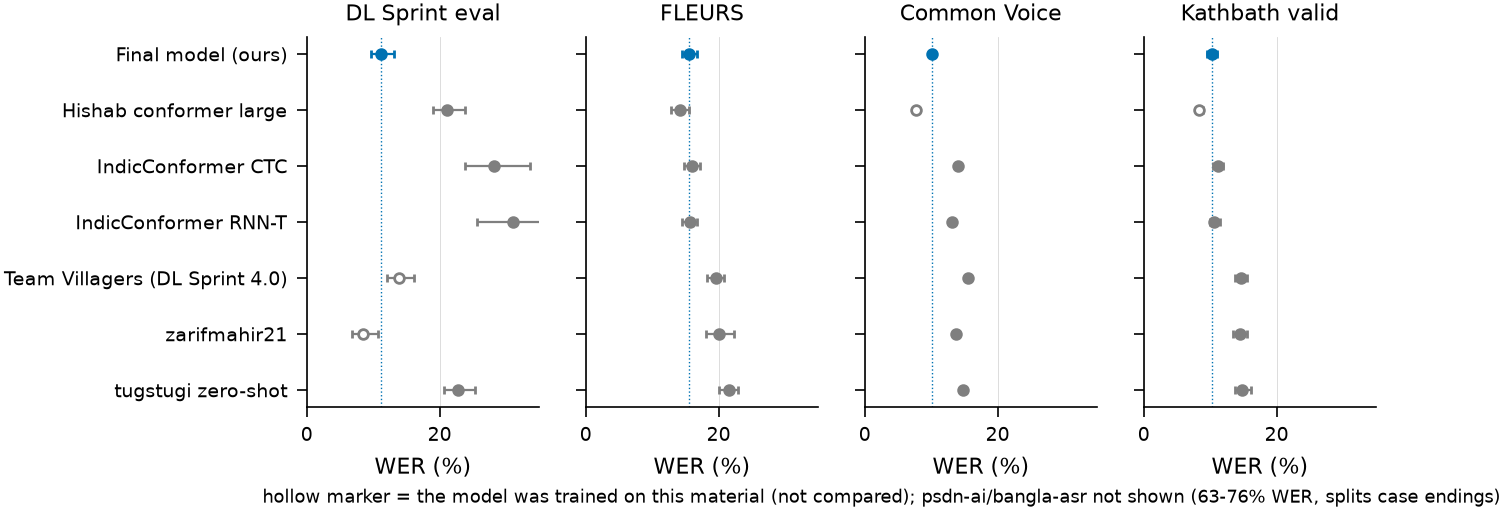

In [4]:
figure("f14_baselines")

## Is zarifmahir21's DL Sprint score real?
It is the only model ahead on DL Sprint eval, and it was trained on DL Sprint 4.0 data. On the eval clips whose
reference the annotators corrected (notebook 7), a recognizer should be closer to the corrected text; a model that
learned these transcripts reproduces the original errors:

In [5]:
pd.read_csv(ROOT / "results/labels/memorization_check.csv").round(4)

,system,clips,wer_vs_original,wer_vs_corrected,closer_to_original,closer_to_corrected
0,zarifmahir21 (trained on DL Sprint 4.0 data),92,0.1277,0.1387,43,27
1,Team Villagers (trained on DL Sprint 4.0 data),92,0.1636,0.1557,24,39
2,final model,92,0.1267,0.1154,18,45
3,M1 (DL Sprint train split only),92,0.1324,0.1233,23,45
4,tugstugi zero-shot,92,0.2462,0.2295,15,48
5,Hishab conformer large,92,0.2311,0.2166,17,46


In [6]:
pd.Series(load("results/contamination/zarif_overlap.json"))

dataset                           zarifmahir21/bengali-asr-chunked
clips                                                        13547
hours                                                        100.1
dlsprint_recordings_in_dataset                                 112
our_eval_recordings_in_dataset                                  22
our_eval_recordings                                             22
eval_8gram_passages_found                                    13136
eval_8gram_passages                                          13137
fleurs_8gram_passages_found                                      0
fleurs_8gram_passages                                         1845
dtype: object

It is the only system closer to the erroneous transcripts. The direct check confirms why: its public training set contains all 22 of our evaluation recordings, and almost every eight-word passage of our references occurs in it.

## Reported results of larger models (not re-scored)
Published Bengali numbers on the same public test sets; other normalizers and sometimes other splits, so indicative only.

| Model | Reported | Final model, same set | Source |
|---|---|---|---|
| IndicWhisper | WER Kathbath 16.6, Common Voice 24.7, FLEURS 20.9 | 10.28, 10.13, 15.60 | Vistaar, arXiv:2305.15386 |
| Omnilingual ASR 7B (Meta) | WER 17.41 on Common Voice + FLEURS combined | FLEURS 15.60, CV 10.13 | BuzzASR, arXiv:2609.09554 |
| MMS-1B (Meta) | WER 33.89, same combined set | | BuzzASR, arXiv:2609.09554 |
| SeamlessM4T v2 large | CER about 9.0 on FLEURS | CER 4.37 | Fleurs-SLU, arXiv:2501.06117 |
| Voxtral-Mini 3B Bangla fine-tune (non-commercial) | FLEURS WER 14.73 / CER 4.78 | 15.60 / CER 4.37 | model card |

**Next:** the references themselves may be wrong. Notebook 7 checks them by hand.